# 02. Khám phá dữ liệu (EDA)

**Mục tiêu:** hiểu phân phối của năng lượng và quan hệ của nó với các biến biết trước khi bay; rút ra ít nhất 3 insight có bằng chứng.

**Đầu vào:** `data/processed/flight_level.csv`

**Đầu ra:** hình trong `reports/figures/`, 3 insight cho báo cáo D2

## 0. Chuẩn bị

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats   # kiểm định thống kê (nếu báo lỗi: pip install scipy)

# Gốc repo: chạy notebook từ thư mục notebooks/ hay từ gốc đều được
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
SEED = 301

In [3]:
# Bảng một chuyến một dòng, đã làm sạch ở notebook 01
df = pd.read_csv(PROCESSED / "flight_level.csv")
print("Kích thước:", df.shape)
df.head()

Kích thước: (192, 11)


,flight,speed,payload,altitude,route,date,local_time,thoi_gian_s,P_tb_W,P_max_W,E_Wh
0,1,4.0,0.0,25,R5,2019-04-07,10:13,200.7,390.047110,724.557377,21.765760
1,2,4.0,0.0,50,R5,2019-04-07,10:23,271.2,336.631861,820.169833,25.374148
2,3,6.0,0.0,25,R5,2019-04-07,10:33,180.1,341.261039,754.444448,17.090203
3,4,8.0,0.0,25,R5,2019-04-07,10:48,171.0,309.511243,765.562258,14.701160
4,5,4.0,0.0,25,R2,2019-04-07,11:05,217.0,316.418567,706.827986,19.048959


## 1. Data dictionary

- [x] Mỗi cột: kiểu, ý nghĩa, đơn vị, vai trò → bảng dưới (giống mục 5.2 của notebook 01)

| Cột | Kiểu | Ý nghĩa | Đơn vị | Vai trò |
|---|---|---|---|---|
| `flight` | số nguyên | Mã chuyến bay | | ID |
| `speed` | số thực | Tốc độ ngang được lập trình | m/s | **Feature trước bay** |
| `payload` | số thực | Khối lượng hàng chở | g | **Feature trước bay** |
| `altitude` | số nguyên | Độ cao bay cài đặt | m | **Feature trước bay** |
| `route` | chữ | Tên đường bay | | Tra cứu, phân tích lỗi |
| `date`, `local_time` | chữ | Ngày, giờ bay | | Tra cứu |
| `thoi_gian_s` | số thực | Thời gian ghi của chuyến | s | Kết quả **sau bay** |
| `P_tb_W`, `P_max_W` | số thực | Công suất trung bình, lớn nhất | W | Kết quả **sau bay** |
| `E_Wh` | số thực | Năng lượng tiêu thụ cả chuyến | Wh | **Target** |

In [4]:
df.dtypes

flight           int64
speed          float64
payload        float64
altitude         int64
route              str
date               str
local_time         str
thoi_gian_s    float64
P_tb_W         float64
P_max_W        float64
E_Wh           float64
dtype: object

**Thiết kế thí nghiệm:** mỗi feature chỉ có vài mức cố định (tốc độ 5 mức, tải 3 mức, độ cao 4 mức), nên dù là số, có thể coi chúng như **nhóm**. Đếm số chuyến ở mỗi mức:

In [5]:
for cot in ["speed", "payload", "altitude"]:
    print(df[cot].value_counts().sort_index().to_dict())

{4.0: 40, 6.0: 38, 8.0: 36, 10.0: 41, 12.0: 37}
{0.0: 66, 250.0: 61, 500.0: 65}
{25: 53, 50: 47, 75: 47, 100: 45}


**Kết luận:** mỗi mức có 36–66 chuyến, khá cân bằng, đủ để so sánh giữa các nhóm.

## 2. Phân phối target

- [x] Histogram năng lượng. Trung bình, nhỏ nhất, lớn nhất? → mục 2
- [x] Có giá trị ngoại lai không? → dùng quy tắc IQR

In [6]:
df["E_Wh"].describe().round(2)

count    192.00
mean      21.27
std        4.90
min       12.99
25%       17.62
50%       20.79
75%       24.53
max       37.75
Name: E_Wh, dtype: float64

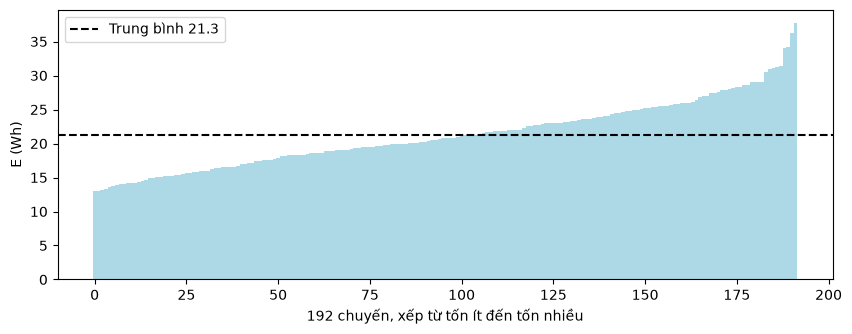

In [7]:
e = df["E_Wh"].sort_values().values
plt.figure(figsize=(10, 3.5))
plt.bar(range(len(e)), e, width=1, color="lightblue")
plt.axhline(e.mean(), color="black", linestyle="--", label=f"Trung bình {e.mean():.1f}")
plt.xlabel("192 chuyến, xếp từ tốn ít đến tốn nhiều")
plt.ylabel("E (Wh)")
plt.legend()
plt.show()

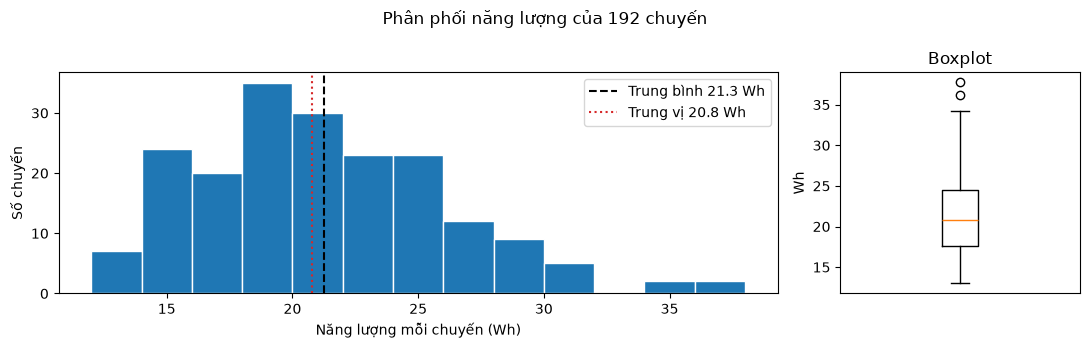

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [3, 1]})

ax[0].hist(df["E_Wh"], bins=range(12, 40, 2), color="tab:blue", edgecolor="white")
ax[0].axvline(df["E_Wh"].mean(), color="black", linestyle="--", label=f"Trung bình {df['E_Wh'].mean():.1f} Wh")
ax[0].axvline(df["E_Wh"].median(), color="tab:red", linestyle=":", label=f"Trung vị {df['E_Wh'].median():.1f} Wh")
ax[0].set_xlabel("Năng lượng mỗi chuyến (Wh)")
ax[0].set_ylabel("Số chuyến")
ax[0].legend()

ax[1].boxplot(df["E_Wh"])
ax[1].set_xticks([])
ax[1].set_ylabel("Wh")
ax[1].set_title("Boxplot")

fig.suptitle("Phân phối năng lượng của 192 chuyến")
plt.tight_layout()
plt.savefig(FIGURES / "eda_phan_phoi_target.png", dpi=150)
plt.show()

**Tìm ngoại lai bằng quy tắc IQR:** IQR = Q3 − Q1 (khoảng chứa 50% chuyến ở giữa). Chuyến nào lớn hơn Q3 + 1,5 × IQR hoặc nhỏ hơn Q1 − 1,5 × IQR được coi là ngoại lai. Đây cũng là cách boxplot vẽ các chấm rời.

In [9]:
q1, q3 = df["E_Wh"].quantile([0.25, 0.75])
iqr = q3 - q1
can_tren, can_duoi = q3 + 1.5 * iqr, q1 - 1.5 * iqr
print(f"Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f} -> ngoại lai nếu ngoài [{can_duoi:.1f}, {can_tren:.1f}] Wh")
df[(df["E_Wh"] > can_tren) | (df["E_Wh"] < can_duoi)][["flight", "speed", "payload", "altitude", "route", "E_Wh"]]

Q1 = 17.6, Q3 = 24.5, IQR = 6.9 -> ngoại lai nếu ngoài [7.2, 34.9] Wh


,flight,speed,payload,altitude,route,E_Wh
65,126,4.0,500.0,100,R1,36.219851
188,272,4.0,250.0,50,R6,37.747051


**Kết luận:**
- Năng lượng từ 13,0 đến 37,7 Wh, trung bình 21,3 Wh, trung vị 20,8 Wh. Trung bình lớn hơn trung vị một chút: phân phối **lệch phải** nhẹ (có ít chuyến tốn rất nhiều).
- Có 2 ngoại lai theo IQR. Chuyến **126** (4 m/s, 500 g, 100 m) là tổ hợp "nặng nhất": bay chậm nhất, chở nặng nhất, bay cao nhất, nên tốn nhiều là hợp lý. Chuyến **272** là route R6 (đã biết tốn hơn R1 ở notebook 01).
- Cả 2 đều có lý do vật lý rõ ràng, không phải lỗi dữ liệu → **giữ lại**.

## 3. Quan hệ feature với target

- [x] Năng lượng thay đổi thế nào theo payload, tốc độ, độ cao? → bảng trung bình + kiểm định
- [x] Scatter giữa feature và năng lượng → hình 3 ô

In [10]:
# Năng lượng trung bình (và độ lệch chuẩn, số chuyến) ở mỗi mức của từng feature
for cot in ["speed", "payload", "altitude"]:
    print(df.groupby(cot)["E_Wh"].agg(["mean", "std", "count"]).round(1), "\n")

       mean  std  count
speed                  
4.0    27.0  4.2     40
6.0    22.1  3.7     38
8.0    19.8  3.6     36
10.0   18.6  3.5     41
12.0   18.6  3.5     37 

         mean  std  count
payload                  
0.0      19.2  3.8     66
250.0    21.5  4.8     61
500.0    23.1  5.2     65 

          mean  std  count
altitude                  
25        17.4  3.7     53
50        20.5  4.6     47
75        22.6  3.6     47
100       25.2  3.9     45 



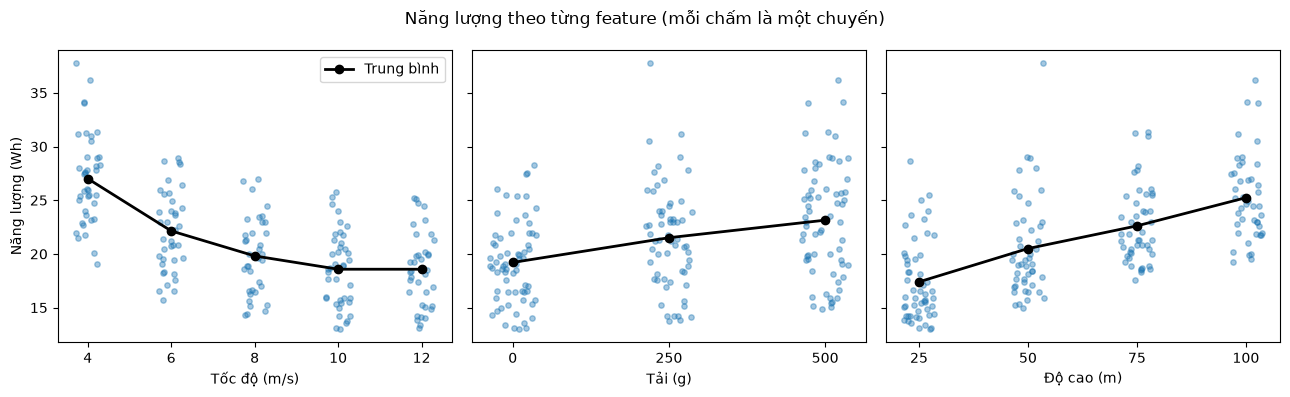

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
ten = {"speed": "Tốc độ (m/s)", "payload": "Tải (g)", "altitude": "Độ cao (m)"}
rng = np.random.default_rng(SEED)

for ax, cot in zip(axes, ["speed", "payload", "altitude"]):
    muc = sorted(df[cot].unique())
    # Chấm từng chuyến, rung ngang một chút cho khỏi đè lên nhau
    x = df[cot].map({m: i for i, m in enumerate(muc)}) + rng.uniform(-0.15, 0.15, len(df))
    ax.scatter(x, df["E_Wh"], alpha=0.4, s=15, color="tab:blue")
    # Đường nối trung bình mỗi mức
    tb = df.groupby(cot)["E_Wh"].mean()
    ax.plot(range(len(muc)), tb.values, color="black", marker="o", linewidth=2, label="Trung bình")
    ax.set_xticks(range(len(muc)))
    ax.set_xticklabels([int(m) for m in muc])
    ax.set_xlabel(ten[cot])
axes[0].set_ylabel("Năng lượng (Wh)")
axes[0].legend()
fig.suptitle("Năng lượng theo từng feature (mỗi chấm là một chuyến)")
plt.tight_layout()
plt.savefig(FIGURES / "eda_feature_vs_target.png", dpi=150)
plt.show()

**Kiểm định thống kê:** chênh lệch giữa các nhóm có thật hay chỉ do ngẫu nhiên? Dùng 2 kiểm định cho mỗi feature:
- **ANOVA một chiều:** so trung bình của nhiều nhóm. Giả định mỗi nhóm có phân phối gần chuẩn.
- **Kruskal–Wallis:** phiên bản không cần giả định phân phối chuẩn (so thứ hạng). Dùng thêm vì target hơi lệch phải.

Nếu p-value < 0,05 thì kết luận năng lượng **thật sự khác nhau** giữa các mức.

In [12]:
for cot in ["speed", "payload", "altitude"]:
    nhom = [g["E_Wh"].values for _, g in df.groupby(cot)]
    anova = stats.f_oneway(*nhom)
    kw = stats.kruskal(*nhom)
    print(f"{cot:9s} | ANOVA p = {anova.pvalue:.1e} | Kruskal-Wallis p = {kw.pvalue:.1e}")

speed     | ANOVA p = 3.3e-22 | Kruskal-Wallis p = 1.1e-15
payload   | ANOVA p = 1.4e-05 | Kruskal-Wallis p = 3.9e-05
altitude  | ANOVA p = 1.3e-17 | Kruskal-Wallis p = 3.4e-16


**Kết luận:** cả 3 feature đều có p-value rất nhỏ (< 0,001) ở cả 2 kiểm định, tức năng lượng thật sự khác nhau giữa các mức tốc độ, tải và độ cao. Cả 3 feature đều đáng đưa vào mô hình.

### 3.1 Vì sao bay nhanh lại tốn ít năng lượng hơn?

Năng lượng = công suất trung bình × thời gian bay. Xem 2 thành phần này thay đổi thế nào theo tốc độ:

In [13]:
df.groupby("speed")[["P_tb_W", "thoi_gian_s", "E_Wh"]].mean().round(1)

,P_tb_W,thoi_gian_s,E_Wh
speed,,,
4.0,411.4,238.8,27.0
6.0,413.9,192.5,22.1
8.0,398.3,179.3,19.8
10.0,400.1,167.1,18.6
12.0,403.4,166.3,18.6


**Kết luận:** công suất trung bình gần như **không đổi** (khoảng 400–414 W) ở mọi tốc độ, nhưng thời gian bay giảm từ khoảng 239 s (4 m/s) xuống 166 s (12 m/s). Vậy năng lượng giảm chủ yếu vì **bay nhanh thì xong sớm**. Từ 10 lên 12 m/s thời gian gần như không giảm nữa (167 → 166 s), nên năng lượng cũng dừng giảm.

### 3.2 Vì sao từ 10 lên 12 m/s không giảm nữa?

Ở notebook 01 đã thấy dấu hiệu: drone có thể không đạt tốc độ cài đặt. Kiểm bằng tốc độ thật trong telemetry (`velocity_x`, `velocity_y`):

In [14]:
# Tốc độ ngang thật = căn(vx^2 + vy^2); lấy mức phân vị 90% mỗi chuyến (tốc độ khi bay hành trình)
tele = pd.read_csv(RAW / "flights.csv", usecols=["flight", "velocity_x", "velocity_y"])
tele["v_ngang"] = np.hypot(tele["velocity_x"], tele["velocity_y"])
v_that = tele.groupby("flight")["v_ngang"].quantile(0.9).rename("v_that")

df = df.join(v_that, on="flight")
df.groupby("speed")["v_that"].describe()[["mean", "min", "max"]].round(2)

,mean,min,max
speed,,,
4.0,4.03,3.99,4.09
6.0,5.97,5.94,6.03
8.0,7.86,7.76,8.06
10.0,9.65,9.04,9.82
12.0,10.66,8.16,11.59


**Kết luận:** ở 4, 6, 8 m/s drone bay đúng tốc độ cài đặt. Nhưng cài 10 m/s chỉ đạt khoảng 9,7 m/s, và cài **12 m/s chỉ đạt khoảng 10,7 m/s**. Vì drone không thật sự bay nhanh hơn, thời gian bay và năng lượng ở 12 m/s gần như bằng 10 m/s. Quan hệ tốc độ – năng lượng vì thế là **đường cong**, không phải đường thẳng.

Lưu ý: mô hình vẫn dùng tốc độ **cài đặt** (vì đó là thông tin có trước khi bay); tốc độ thật chỉ dùng để giải thích.

### 3.3 Tải và tốc độ cùng lúc

Bảng năng lượng trung bình theo cả tốc độ (hàng) và tải (cột):

In [15]:
df.pivot_table(index="speed", columns="payload", values="E_Wh", aggfunc="mean").round(1)

payload,0.0,250.0,500.0
speed,,,
4.0,24.0,27.5,29.7
6.0,19.7,22.2,24.5
8.0,18.0,19.7,21.7
10.0,17.0,19.0,19.8
12.0,17.0,18.5,20.2


**Kết luận:** ở mọi tốc độ, chở nặng hơn đều tốn hơn (đọc theo hàng); ở mọi mức tải, bay nhanh hơn đều tốn ít hơn (đọc theo cột). Hai tác động cộng dồn khá đều đặn: tổ hợp tốn nhất là 4 m/s + 500 g (29,7 Wh), tiết kiệm nhất là 10–12 m/s + 0 g (17,0 Wh).

## 4. Tương quan

- [x] Heatmap tương quan. Biến nào quan trọng?
- [x] Biến nào tương quan cao nhưng không được dùng vì là kết quả sau bay?

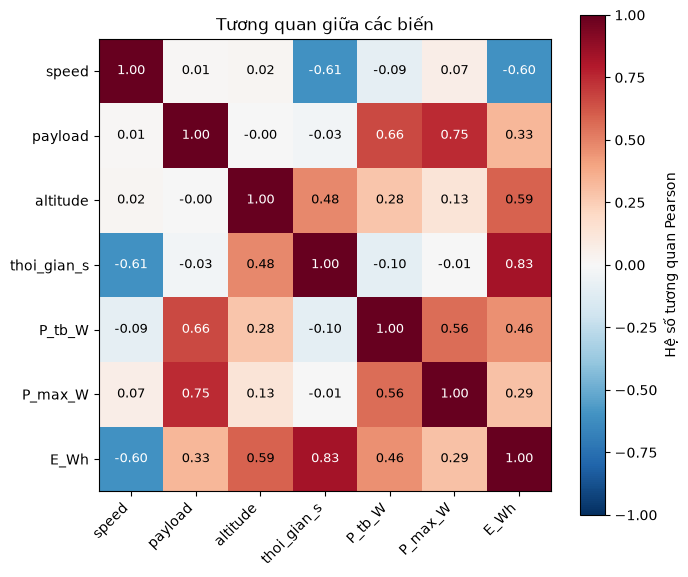

In [16]:
cot_so = ["speed", "payload", "altitude", "thoi_gian_s", "P_tb_W", "P_max_W", "E_Wh"]
tq = df[cot_so].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(tq, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cot_so)))
ax.set_xticklabels(cot_so, rotation=45, ha="right")
ax.set_yticks(range(len(cot_so)))
ax.set_yticklabels(cot_so)
for i in range(len(cot_so)):
    for j in range(len(cot_so)):
        ax.text(j, i, f"{tq.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(tq.iloc[i, j]) > 0.6 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="Hệ số tương quan Pearson")
ax.set_title("Tương quan giữa các biến")
plt.tight_layout()
plt.savefig(FIGURES / "eda_tuong_quan.png", dpi=150)
plt.show()

In [17]:
# Tương quan của từng biến với năng lượng, xếp theo độ lớn
tq["E_Wh"].drop("E_Wh").sort_values(key=abs, ascending=False).round(2)

thoi_gian_s    0.83
speed         -0.60
altitude       0.59
P_tb_W         0.46
payload        0.33
P_max_W        0.29
Name: E_Wh, dtype: float64

**Kết luận:**
- Trong 3 feature trước bay: **độ cao (+0,59)** và **tốc độ (−0,60)** tương quan mạnh với năng lượng, **tải (+0,33)** yếu hơn. Dấu âm của tốc độ: bay nhanh thì tốn ít.
- 3 feature gần như **không tương quan với nhau** (|r| ≤ 0,02) vì thí nghiệm được thiết kế theo lưới. Điều này tốt cho mô hình hồi quy: không có đa cộng tuyến, mỗi hệ số đo đúng tác động riêng của từng feature.
- **`thoi_gian_s` tương quan mạnh nhất (+0,83)** nhưng chỉ biết **sau khi bay**. Tương tự `P_tb_W`, `P_max_W`. Nếu đưa vào mô hình sẽ là **rò rỉ dữ liệu** (data leakage): điểm số đẹp nhưng không dùng được để lên kế hoạch trước chuyến bay → **không dùng**.
- Hệ số Pearson chỉ đo quan hệ **đường thẳng**. Quan hệ tốc độ – năng lượng là đường cong (mục 3.2), nên −0,60 có thể đánh giá thấp mức ảnh hưởng thật của tốc độ.

## 5. Ba insight

- [x] Insight 1 + con số + hình
- [x] Insight 2 + con số + hình
- [x] Insight 3 + con số + hình
- [x] Mỗi insight liên quan RQ thế nào?

**Insight 1. Bay nhanh tiết kiệm năng lượng, nhưng chỉ tới khoảng 10 m/s.**
- *Bằng chứng:* năng lượng trung bình giảm từ 27,0 Wh (4 m/s) xuống 18,6 Wh (10 m/s), rồi giữ nguyên 18,6 Wh ở 12 m/s. Công suất trung bình gần như không đổi (khoảng 400–414 W), chỉ có thời gian bay giảm. Ở 12 m/s drone thật ra chỉ bay khoảng 10,7 m/s. Kruskal–Wallis p < 0,001. Hình: `eda_feature_vs_target.png`.
- *Liên quan RQ:* tốc độ là feature quan trọng, nhưng tác động **không tuyến tính**. Mô hình đường thẳng có thể dự đoán sai ở 2 đầu; nên thử thêm mô hình bắt được đường cong (ví dụ cây quyết định, hoặc thêm biến tốc độ bình phương).

**Insight 2. Bay càng cao càng tốn, khoảng +2,6 Wh cho mỗi 25 m.**
- *Bằng chứng:* trung bình 17,4 Wh (25 m) → 20,5 → 22,6 → 25,2 Wh (100 m), tăng khá đều; tương quan +0,59, ANOVA p < 0,001. Bay cao phải leo và hạ nhiều hơn, thời gian bay cũng dài hơn (tương quan độ cao – thời gian +0,48).
- *Liên quan RQ:* độ cao là feature mạnh và gần **tuyến tính**, phù hợp với mô hình hồi quy tuyến tính làm baseline.

**Insight 3. Chở 500 g tốn hơn không chở khoảng 20%, qua đường tăng công suất chứ không phải tăng thời gian.**
- *Bằng chứng:* 19,2 Wh (0 g) → 21,5 Wh (250 g) → 23,1 Wh (500 g), ANOVA p < 0,001. Tải tương quan mạnh với công suất trung bình (+0,66) nhưng gần như không với thời gian bay (−0,03): chở nặng thì motor phải gắng hơn, còn quãng đường thì như cũ.
- *Liên quan RQ:* tải có tác động **độc lập** với tốc độ (bảng 3.3), nên mô hình cần cả 2. Tải tương quan yếu nhất (+0,33) nhưng vẫn có ý nghĩa thống kê.

**Thêm (không tính vào 3 insight):** `thoi_gian_s` tương quan +0,83 với năng lượng nhưng là thông tin sau bay → loại khỏi feature để tránh rò rỉ dữ liệu.

## Ghi chú cho báo cáo

**Bước này tìm ra gì** (dùng cho phần *EDA insights* của D2):

1. **Target:** 192 chuyến, năng lượng 13,0–37,7 Wh, trung bình 21,3 Wh, lệch phải nhẹ. 2 ngoại lai (chuyến 126, 272) có lý do vật lý, giữ lại.
2. **Cả 3 feature đều có ý nghĩa** (ANOVA và Kruskal–Wallis, p < 0,001). 3 feature độc lập với nhau nhờ thiết kế lưới.
3. **3 insight:** tốc độ (giảm năng lượng, bão hoà sau 10 m/s, không tuyến tính); độ cao (+2,6 Wh mỗi 25 m, gần tuyến tính); tải (+20% từ 0 lên 500 g, qua công suất).
4. **Rò rỉ dữ liệu:** thời gian bay, công suất trung bình và lớn nhất chỉ có sau khi bay, không dùng làm feature.

**Gợi ý cho D3:** baseline hồi quy tuyến tính với 3 feature; mô hình so sánh nên bắt được quan hệ cong của tốc độ.

**Hình cho báo cáo:** `eda_phan_phoi_target.png`, `eda_feature_vs_target.png`, `eda_tuong_quan.png`.